# Validate the solar position UDF against Sentinel-2 per-pixel sun angles

Run on branch `hv_fix_solarangles` (UDF solves the overpass time from the S2 sun angles). The UDF runs on CDSE openEO (batch jobs, whole tile, winter + summer scene).

Reference: the 5 km sun-angle grid (`Sun_Angles_Grid`, 23x23) in each granule's `MTD_TL.xml`, read from CDSE S3 (`eodata`).

Compared per grid point:

| method | what it is |
|---|---|
| `tile_mean` | `Mean_Sun_Angle` from MTD_TL (constant per scene) |
| `openeo_sun_bands` | openEO `sunZenithAngles`/`sunAzimuthAngles` bands (what the pipeline used before the UDF) |
| `openeo_udf_context` | UDF on CDSE with `context["s2_tiles"]` from `s2_tile_sun_angles()` (batch pipeline) |
| `openeo_udf_bands` | UDF on CDSE without context, sun bands only (UDP fallback) |
| `spa_sensing_time` | pvlib SPA at the MTD `SENSING_TIME` per point (best achievable with a known time) |

Note: the STAC `product_metadata` asset (`MTD_MSIL2A.xml`) has no angle grids; the grids are in the granule `MTD_TL.xml`.

Auth: CDSE username/password (env `CDSE_USERNAME` / `CDSE_PASSWORD`, else prompted) -> access token -> temporary S3 key pair, deleted right after the MTD download. openEO uses its own OIDC login.

In [7]:
%pip install -q -e .. boto3 pystac-client pvlib matplotlib

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import getpass
import json
import os
import re
import sys
import time
import xml.etree.ElementTree as ET
from pathlib import Path
from urllib.parse import urlparse

import boto3
import matplotlib.pyplot as plt
import numpy as np
import openeo
import pandas as pd
import pystac_client
import requests
from openeo import UDF
from pvlib import solarposition
from pyproj import Transformer
from shapely.geometry import box

# Make the local package importable when running from the notebook folder.
for base in [Path.cwd(), *Path.cwd().parents]:
    src = base / "src"
    if src.exists() and str(src) not in sys.path:
        sys.path.insert(0, str(src))
        break

from openeo_mountains_snow.config import SOLAR_POSITION_UDF
from openeo_mountains_snow.common.sun import s2_tile_sun_angles

LON, LAT = 11.125, 46.525          # point of interest (Dolomites)
PERIOD = "2023-01-01/2023-12-31"   # one scene per month is kept
STAC_URL = "https://stac.dataspace.copernicus.eu/v1"
TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
S3_KEYS_URL = "https://s3-keys-manager.cloudferro.com/api/user/credentials"

cdse_username = os.environ.get("CDSE_USERNAME") or input("CDSE username: ")
cdse_password = os.environ.get("CDSE_PASSWORD") or getpass.getpass("CDSE password: ")

# CDSE login -> access token -> temporary S3 key pair (deleted again after the MTD download)
token = requests.post(
    TOKEN_URL,
    timeout=30,
    data={
        "client_id": "cdse-public",
        "grant_type": "password",
        "username": cdse_username,
        "password": cdse_password,
    },
)
token.raise_for_status()
headers = {"Authorization": f"Bearer {token.json()['access_token']}", "Accept": "application/json"}

keys = requests.post(S3_KEYS_URL, headers=headers, timeout=30)
keys.raise_for_status()
s3_creds = keys.json()
time.sleep(5)  # key pair needs a moment to become active

s3 = boto3.client(
    "s3",
    endpoint_url="https://eodata.dataspace.copernicus.eu",
    aws_access_key_id=s3_creds["access_id"],
    aws_secret_access_key=s3_creds["secret"],
    region_name="default",
)

## 1. STAC search: one scene per month on the dominant MGRS tile

In [3]:
from pystac_client.exceptions import APIError

stac = pystac_client.Client.open(STAC_URL)


def search(period, tries=5):
    # CDSE STAC replica sometimes cancels long queries (SerializationError); short queries + retry
    for k in range(tries):
        try:
            return list(stac.search(
                collections=["sentinel-2-l2a"],
                intersects={"type": "Point", "coordinates": [LON, LAT]},
                datetime=period,
            ).items())
        except APIError as e:
            if "SerializationError" not in str(e) or k == tries - 1:
                raise
            time.sleep(2 ** k)


start, end = PERIOD.split("/")
months = pd.date_range(start, end, freq="MS")
items = [i for m in months for i in search(f"{m:%Y-%m-%d}/{(m + pd.offsets.MonthEnd()):%Y-%m-%d}")]


def tile_of(item):
    return re.search(r"_T(\d{2}[A-Z]{3})_", item.id).group(1)


TILE = pd.Series([tile_of(i) for i in items]).mode()[0]
items = sorted((i for i in items if tile_of(i) == TILE), key=lambda i: i.datetime)
picked = list({i.datetime.strftime("%Y-%m"): i for i in items}.values())
print(f"tile {TILE}: {len(items)} items, {len(picked)} picked")
for i in picked:
    print(" ", i.id)

tile 32TPS: 144 items, 12 picked
  S2B_MSIL2A_20230131T102149_N0510_R065_T32TPS_20240811T111953
  S2B_MSIL2A_20230227T101029_N0510_R022_T32TPS_20240816T115944
  S2B_MSIL2A_20230329T100629_N0510_R022_T32TPS_20240823T220348
  S2B_MSIL2A_20230428T100559_N0510_R022_T32TPS_20240831T193714
  S2B_MSIL2A_20230531T101559_N0510_R065_T32TPS_20240908T144756
  S2B_MSIL2A_20230630T101609_N0510_R065_T32TPS_20241003T054424
  S2B_MSIL2A_20230730T101609_N0510_R065_T32TPS_20241018T205646
  S2A_MSIL2A_20230831T100601_N0510_R022_T32TPS_20241018T054233
  S2A_MSIL2A_20230930T100811_N0510_R022_T32TPS_20241106T092217
  S2A_MSIL2A_20231030T101141_N0510_R022_T32TPS_20241106T203342
  S2A_MSIL2A_20231129T101351_N0510_R022_T32TPS_20241110T221337
  S2A_MSIL2A_20231229T101431_N0510_R022_T32TPS_20231229T122250


## 2. Download and parse `MTD_TL.xml` from S3

In [4]:
def mtd_tl_key(item):
    """S3 key of the granule MTD_TL.xml; falls back to listing the SAFE GRANULE folder."""
    hrefs = [h for a in item.assets.values()
             for h in [a.href, *(v.get("href", "") for v in a.extra_fields.get("alternate", {}).values())]
             if h.startswith("s3://")]
    keys = [urlparse(h).path.lstrip("/") for h in hrefs]
    key = next((k for k in keys if k.endswith("MTD_TL.xml")), None)
    if key:
        return key
    safe = next(m.group(1) for k in keys if (m := re.match(r"(.*?\.SAFE)", k)))
    listing = s3.list_objects_v2(Bucket="eodata", Prefix=f"{safe}/GRANULE/")
    return next(o["Key"] for o in listing["Contents"] if o["Key"].endswith("MTD_TL.xml"))


def local(e):
    return e.tag.rsplit("}", 1)[-1]


def first(node, name):
    return next(e for e in node.iter() if local(e) == name)


def parse_mtd_tl(xml):
    root = ET.fromstring(xml)
    geo = next(g for g in root.iter() if local(g) == "Geoposition" and g.get("resolution") == "10")
    grid = first(root, "Sun_Angles_Grid")

    def values(name):
        node = first(grid, name)
        return np.array([[float(v) for v in row.text.split()] for row in node.iter() if local(row) == "VALUES"])

    zen, azi = values("Zenith"), values("Azimuth")
    dx, dy = float(first(grid, "COL_STEP").text), float(first(grid, "ROW_STEP").text)
    ulx, uly = float(first(geo, "ULX").text), float(first(geo, "ULY").text)
    mean = first(root, "Mean_Sun_Angle")
    return dict(
        epsg=int(first(root, "HORIZONTAL_CS_CODE").text.split(":")[1]),
        sensing_time=pd.Timestamp(first(root, "SENSING_TIME").text),
        x=ulx + dx * np.arange(zen.shape[1]),   # grid nodes sit on the UL corner + k*step
        y=uly - dy * np.arange(zen.shape[0]),
        zenith=zen,
        azimuth=azi,
        mean_zenith=float(first(mean, "ZENITH_ANGLE").text),
        mean_azimuth=float(first(mean, "AZIMUTH_ANGLE").text),
    )


try:
    mtd = {i.id: parse_mtd_tl(s3.get_object(Bucket="eodata", Key=mtd_tl_key(i))["Body"].read()) for i in picked}
finally:
    r = requests.delete(f"{S3_KEYS_URL}/access_id/{s3_creds['access_id']}", headers=headers, timeout=30)
    print("temporary S3 key deleted" if r.status_code == 204 else f"S3 key delete failed: {r.status_code}")

for sid, m in mtd.items():
    print(f"{m['sensing_time']:%Y-%m-%d %H:%M}  EPSG:{m['epsg']}  grid {m['zenith'].shape}  "
          f"mean zen {m['mean_zenith']:.3f} azi {m['mean_azimuth']:.3f}  "
          f"grid zen {np.nanmin(m['zenith']):.2f}..{np.nanmax(m['zenith']):.2f}")

temporary S3 key deleted
2023-01-31 10:27  EPSG:32632  grid (23, 23)  mean zen 65.324 azi 163.866  grid zen 64.70..65.95
2023-02-27 10:17  EPSG:32632  grid (23, 23)  mean zen 57.029 azi 159.032  grid zen 56.38..57.68
2023-03-29 10:18  EPSG:32632  grid (23, 23)  mean zen 45.191 azi 157.644  grid zen 44.53..45.85
2023-04-28 10:18  EPSG:32632  grid (23, 23)  mean zen 34.335 azi 155.670  grid zen 33.67..35.00
2023-05-31 10:27  EPSG:32632  grid (23, 23)  mean zen 26.218 azi 155.484  grid zen 25.55..26.89
2023-06-30 10:28  EPSG:32632  grid (23, 23)  mean zen 25.487 azi 151.542  grid zen 24.80..26.17
2023-07-30 10:28  EPSG:32632  grid (23, 23)  mean zen 30.093 azi 153.608  grid zen 29.42..30.77
2023-08-31 10:18  EPSG:32632  grid (23, 23)  mean zen 39.794 azi 157.135  grid zen 39.13..40.46
2023-09-30 10:18  EPSG:32632  grid (23, 23)  mean zen 50.353 azi 164.358  grid zen 49.73..50.98
2023-10-30 10:17  EPSG:32632  grid (23, 23)  mean zen 60.930 azi 168.424  grid zen 60.33..61.53
2023-11-29 10:1

## 3. Run the UDF on CDSE openEO, sampled at the MTD grid nodes

One batch job per scene (winter + summer) over the whole tile: the UDF runs on the backend's real chunks, with the `s2_tiles` STAC context (batch pipeline) and without (UDP fallback, sun bands only). Results are sampled at the 23x23 MTD grid nodes with `aggregate_spatial`; nodes outside the 109.8 km tile are NaN.

In [ ]:
import json

import openeo
from openeo import UDF
from shapely.geometry import box

from openeo_mountains_snow.config import SOLAR_POSITION_UDF
from openeo_mountains_snow.common.sun import s2_tile_sun_angles

con = openeo.connect("https://openeo.dataspace.copernicus.eu/").authenticate_oidc()

# winter scene only; the cells below only use it
scenes = [max(mtd, key=lambda s: mtd[s]["mean_zenith"])]
mtd = {sid: mtd[sid] for sid in scenes}
BANDS = ["sunZenithAngles", "sunAzimuthAngles"]
OUT_BANDS = BANDS + ["zenith_context", "azimuth_context", "zenith_bands", "azimuth_bands"]


def grid_lonlat(m):
    to_ll = Transformer.from_crs(m["epsg"], 4326, always_xy=True)
    return to_ll, *to_ll.transform(*np.meshgrid(m["x"], m["y"]))


def submit_openeo(m):
    """Solar UDF on the whole tile on CDSE, with and without the STAC context, sampled at the MTD grid nodes."""
    x, y, epsg = m["x"], m["y"], m["epsg"]
    day = m["sensing_time"].date()
    to_ll, lon, lat = grid_lonlat(m)
    west, south, east, north = x[0], y[0] - 109800, x[0] + 109800, y[0]
    s2 = con.load_collection(
        "SENTINEL2_L2A",
        spatial_extent=dict(west=west, south=south, east=east, north=north, crs=epsg),
        temporal_extent=[str(day), str(day + pd.Timedelta(days=1))],
        bands=BANDS,
    )

    def udf(context, suffix):
        out = s2.apply_dimension(dimension="bands", process=UDF.from_file(str(SOLAR_POSITION_UDF), context=context))
        out = out.rename_labels(dimension="bands", target=BANDS + [f"zenith_{suffix}", f"azimuth_{suffix}"])
        return out.filter_bands([f"zenith_{suffix}", f"azimuth_{suffix}"])

    aoi = box(*to_ll.transform_bounds(west, south, east, north))
    context = {"s2_tiles": s2_tile_sun_angles(aoi, [str(day), str(day)])}   # as the batch pipeline builds it
    cube = s2.merge_cubes(udf(context, "context")).merge_cubes(udf({}, "bands"))   # bands = UDP fallback

    points = {"type": "FeatureCollection", "features": [
        {"type": "Feature", "properties": {}, "geometry": {"type": "Point", "coordinates": [lo, la]}}
        for lo, la in zip(lon.ravel(), lat.ravel())]}
    return cube.aggregate_spatial(points, reducer="mean").create_job(
        out_format="JSON", title=f"solar UDF validation {TILE} {day}").start()


def predict(m, path):
    """Methods vs MTD grid, from a downloaded job result (JSON: one date, per point the OUT_BANDS values)."""
    _, lon, lat = grid_lonlat(m)
    (values,) = json.loads(Path(path).read_text()).values()
    v = np.array([[np.nan if b is None else b for b in (p or [None] * len(OUT_BANDS))] for p in values],
                 dtype=float).reshape(*lon.shape, len(OUT_BANDS))
    t, shape = m["sensing_time"], m["zenith"].shape
    sp = [solarposition.get_solarposition(pd.DatetimeIndex([t]), la, lo)
          for la, lo in zip(lat.ravel(), lon.ravel())]
    return {
        "tile_mean": (np.full(shape, m["mean_zenith"]), np.full(shape, m["mean_azimuth"])),
        "openeo_sun_bands": (v[..., 0], v[..., 1]),                                  # old pipeline input
        "openeo_udf_context": (np.degrees(v[..., 2]), np.degrees(v[..., 3])),        # batch pipeline
        "openeo_udf_bands": (np.degrees(v[..., 4]), np.degrees(v[..., 5])),          # UDP fallback
        "spa_sensing_time": (np.array([s["zenith"].iloc[0] for s in sp]).reshape(shape),
                             np.array([s["azimuth"].iloc[0] for s in sp]).reshape(shape)),
    }


# To run a new job: job = submit_openeo(mtd[scenes[0]]); then use its id in the next cell.


Authenticated using refresh token.


In [22]:
# Reconnect to the finished winter job and download its result.
JOB_ID = "j-2611121443424b99aadd8c56bfaae231"   # solar UDF validation 32TPS 2023-12-29

job = con.job(JOB_ID)
print(job.status())
(sid,) = scenes
path = Path(f"solar_udf_openeo_{mtd[sid]['sensing_time'].date()}.json")
asset = next(a for a in job.get_results().get_assets() if a.key.endswith(".json"))
asset.download(path)

preds = {sid: predict(mtd[sid], path)}


finished


## 4. Error statistics vs the MTD grid

`cos_relerr_max_pct` is the worst relative error on cos(SZA), i.e. on the illumination term used downstream.

In [24]:
def angdiff(a, b):
    return (a - b + 180) % 360 - 180


rows = []
for sid, m in mtd.items():
    for method, (z, a) in preds[sid].items():
        ok = np.isfinite(m["zenith"]) & np.isfinite(m["azimuth"]) & np.isfinite(z) & np.isfinite(a)
        dz = (z - m["zenith"])[ok]
        da = angdiff(a, m["azimuth"])[ok]
        dcos = (np.cos(np.radians(z)) / np.cos(np.radians(m["zenith"])) - 1)[ok]
        rows.append(dict(
            date=m["sensing_time"].date(), method=method, n=ok.sum(),
            zen_bias=dz.mean(), zen_rmse=np.sqrt((dz ** 2).mean()), zen_maxabs=np.abs(dz).max(),
            azi_bias=da.mean(), azi_rmse=np.sqrt((da ** 2).mean()), azi_maxabs=np.abs(da).max(),
            cos_relerr_max_pct=100 * np.abs(dcos).max(),
        ))
err = pd.DataFrame(rows)

pd.options.display.float_format = "{:.3f}".format
summary = err.groupby("method").mean(numeric_only=True).sort_values("zen_rmse")
display(summary)
display(err.pivot(index="date", columns="method", values=["zen_rmse", "azi_rmse"]))

,n,zen_bias,zen_rmse,zen_maxabs,azi_bias,azi_rmse,azi_maxabs,cos_relerr_max_pct
method,,,,,,,,
openeo_udf_context,529.000,-0.000,0.003,0.006,0.003,0.019,0.036,0.032
spa_sensing_time,529.000,0.000,0.004,0.008,-0.000,0.020,0.038,0.038
openeo_udf_bands,529.000,0.009,0.072,0.131,-0.048,0.395,0.683,0.687
openeo_sun_bands,529.000,-0.027,0.288,0.549,-0.056,0.392,0.644,2.860
tile_mean,529.000,0.000,0.302,0.617,0.000,0.408,0.709,3.229


zen_rmse                                      \
method     openeo_sun_bands openeo_udf_bands openeo_udf_context   
date                                                              
2023-12-29            0.288            0.072              0.003   

                                              azi_rmse                   \
method     spa_sensing_time tile_mean openeo_sun_bands openeo_udf_bands   
date                                                                      
2023-12-29            0.004     0.302            0.392            0.395   

                                                          
method     openeo_udf_context spa_sensing_time tile_mean  
date                                                      
2023-12-29              0.019            0.020     0.408

zen_rmse openeo_udf_bands         beats tile mean on 100% of scenes; mean 0.072 vs 0.302 deg
zen_rmse openeo_udf_context       beats tile mean on 100% of scenes; mean 0.003 vs 0.302 deg
azi_rmse openeo_udf_bands         beats tile mean on 100% of scenes; mean 0.395 vs 0.408 deg
azi_rmse openeo_udf_context       beats tile mean on 100% of scenes; mean 0.019 vs 0.408 deg


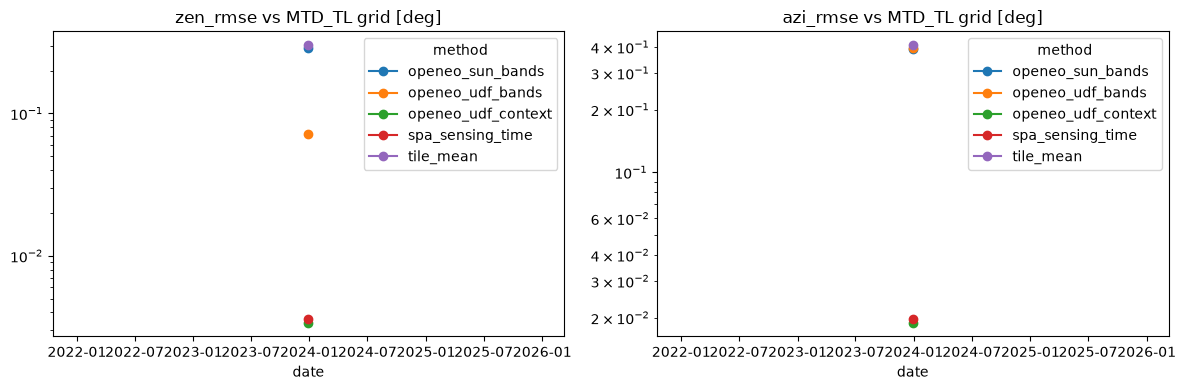

In [20]:
for metric in ["zen_rmse", "azi_rmse"]:
    wide = err.pivot(index="date", columns="method", values=metric)
    for method in [c for c in wide if c.startswith("openeo_udf_")]:
        better = (wide[method] < wide["tile_mean"]).mean()
        print(f"{metric} {method:24s} beats tile mean on {better:4.0%} of scenes; "
              f"mean {summary.loc[method, metric]:.3f} vs {summary.loc['tile_mean', metric]:.3f} deg")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, metric in zip(axes, ["zen_rmse", "azi_rmse"]):
    err.pivot(index="date", columns="method", values=metric).plot(ax=ax, marker="o", logy=True)
    ax.set_title(f"{metric} vs MTD_TL grid [deg]")
plt.tight_layout()

## 5. Error maps for one scene (largest sun zenith = winter)

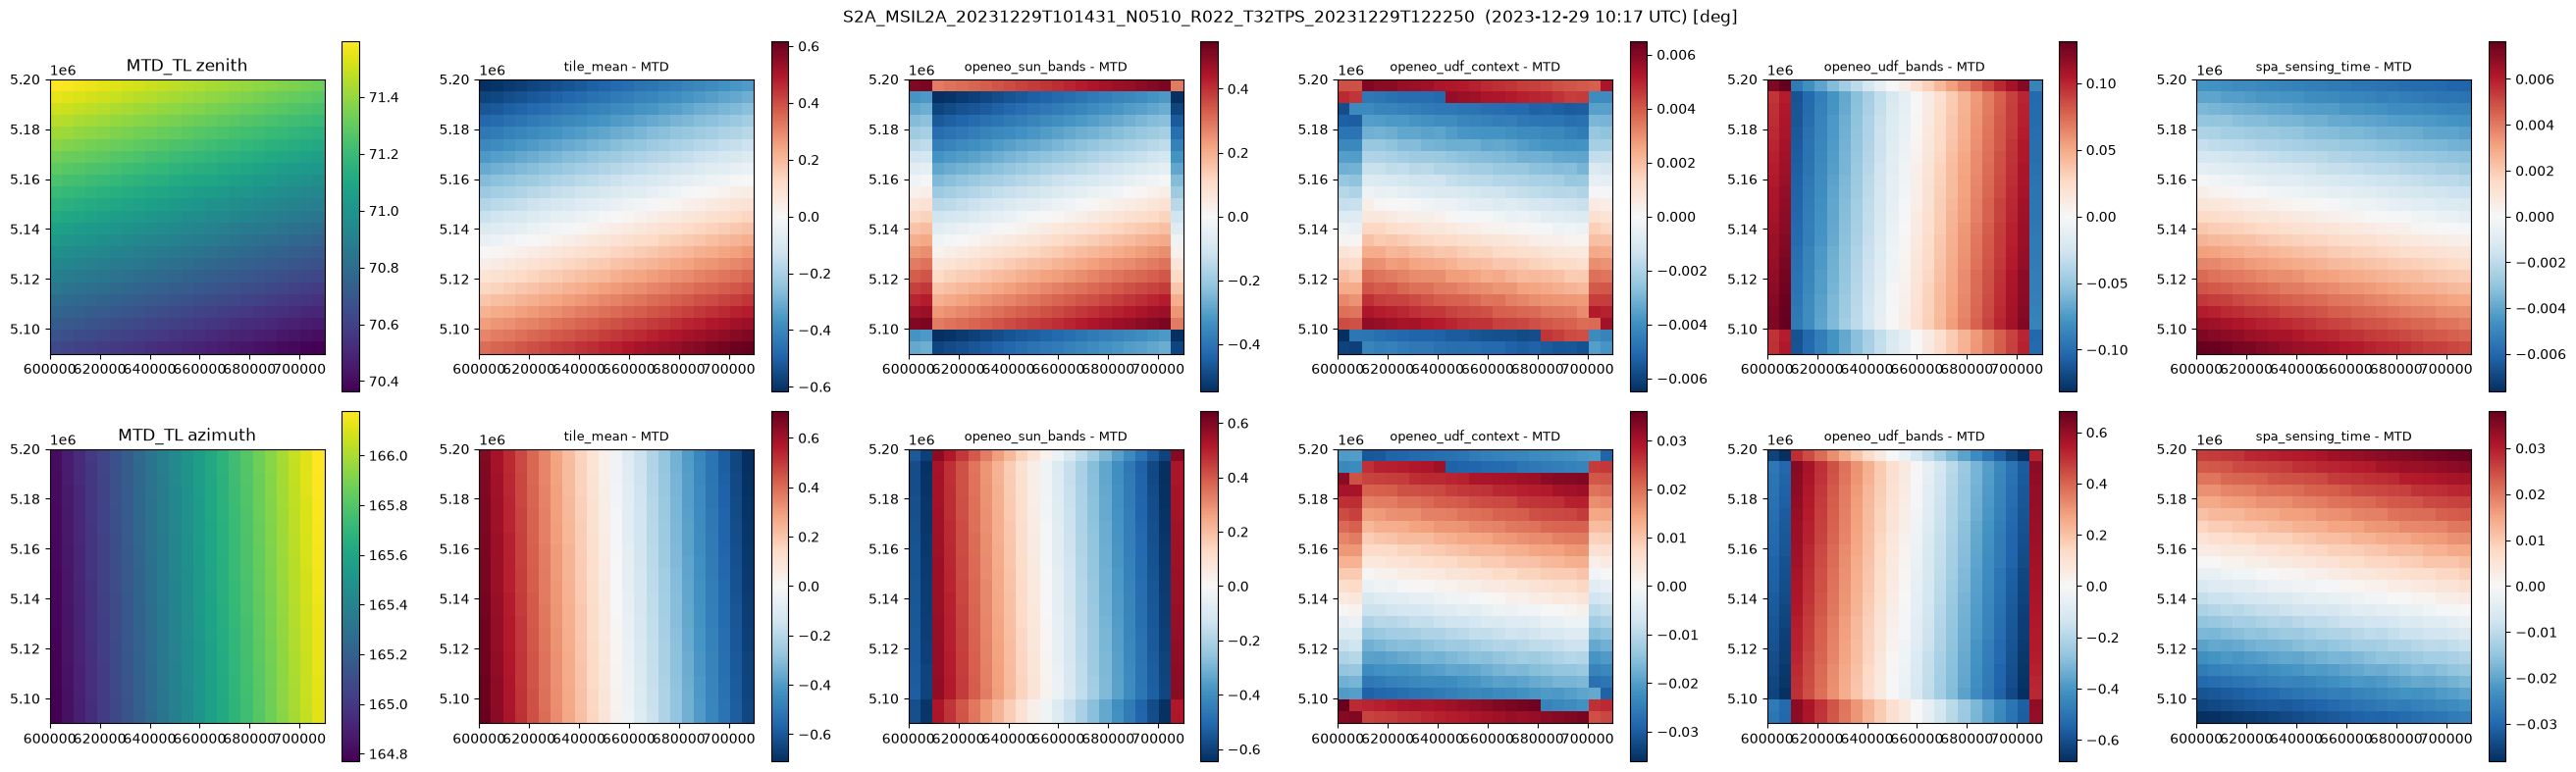

In [21]:
sid = max(mtd, key=lambda s: mtd[s]["mean_zenith"])
m = mtd[sid]
extent = [m["x"][0], m["x"][-1], m["y"][-1], m["y"][0]]

ncol = 1 + len(preds[sid])
fig, axes = plt.subplots(2, ncol, figsize=(4.4 * ncol, 8))
for row, (k, diff) in enumerate([("zenith", lambda p, r: p - r), ("azimuth", angdiff)]):
    ref = m[k]
    im = axes[row, 0].imshow(ref, extent=extent)
    axes[row, 0].set_title(f"MTD_TL {k}")
    plt.colorbar(im, ax=axes[row, 0])
    for col, (method, pred) in enumerate(preds[sid].items(), start=1):
        d = diff(pred[row], ref)
        lim = np.nanmax(np.abs(d)) or 1e-3
        im = axes[row, col].imshow(d, extent=extent, cmap="RdBu_r", vmin=-lim, vmax=lim)
        axes[row, col].set_title(f"{method} - MTD", fontsize=9)
        plt.colorbar(im, ax=axes[row, col])
fig.suptitle(f"{sid}  ({m['sensing_time']:%Y-%m-%d %H:%M} UTC) [deg]")
plt.tight_layout()

## 6. `s2_tile_sun_angles()` (pipeline STAC context) vs MTD_TL

Checks the context the pipeline builds: per picked date, the entry nearest to the MTD tile centre should have the tile centre and the `Mean_Sun_Angle`.

In [ ]:
rows = []
for sid, m in mtd.items():
    t = m["sensing_time"]
    day = f"{t:%Y-%m-%d}"
    to_ll = Transformer.from_crs(m["epsg"], 4326, always_xy=True)
    clon, clat = to_ll.transform(m["x"][0] + 54900, m["y"][0] - 54900)
    tiles = s2_tile_sun_angles(box(LON - 0.01, LAT - 0.01, LON + 0.01, LAT + 0.01), [day, day]).get(day, [])
    if not tiles:
        rows.append(dict(date=day, n_tiles=0))
        continue
    lon, lat, zen, azi = min(tiles, key=lambda e: (e[0] - clon) ** 2 + (e[1] - clat) ** 2)
    rows.append(dict(
        date=day, n_tiles=len(tiles),
        centre_offset_m=np.hypot((lon - clon) * 111320 * np.cos(np.radians(clat)), (lat - clat) * 111320),
        d_zen=zen - m["mean_zenith"], d_azi=angdiff(azi, m["mean_azimuth"]),
    ))
display(pd.DataFrame(rows))